In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

# clock/02 — condition-dataset gaze

Inspect the condition-checking clock results built by
`scripts/clock/build_condition_data.py` (generation + oracle labels + attention)
and scored by `scripts/clock/score_condition_heads.py`.

1. Load one sample + its oracle label and verify generation/labeling worked
   (label viz copied from `clock/01_data.ipynb`).
2. Load aggregated head scores, pick the top-50 step-lookback heads, and show the
   (value-weighted) attention for them on a demo sample
   (viz adapted from `clock/17_clock_multi_attn.ipynb`).

The full model is loaded so §3 can run live generations; §1/§2 work off cached results.

In [2]:
import os
import json
import logging

import numpy as np

from src.utils import env_utils, logging_utils

logging_utils.configure(level=logging.INFO)

# ── config ────────────────────────────────────────────────────────────────────
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
MODEL_SHORT = MODEL_NAME.split("/")[-1]
VERSION = "conditions"

CACHE_ROOT = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "multistep_clock", VERSION, MODEL_SHORT
)
print(f"cache root: {CACHE_ROOT}")
assert os.path.isdir(CACHE_ROOT), CACHE_ROOT

# Full model — §1/§2 only need the tokenizer, but §3 runs live generations.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0,1,2,3,4,5,6,7")
import torch
from src.models import ModelandTokenizer

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
tok = mt.tokenizer
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

cache root: /disk/u/arnab/Codes/Projects/goals/results/multistep_clock/conditions/Qwen2.5-Coder-32B-Instruct
2026-06-23 17:31:15 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-06-23 17:31:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-23 17:31:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-23 17:31:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-23 17:31:15 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Ins

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-23 17:31:37 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-23 17:31:37 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-23 17:31:37 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


## 1. Load a sample + its oracle label

Reconstruct the `LabeledGeneration` from `labels.json` (written by the build
script) and render the spec-span ↔ code-span coloring. Each condition gets a
color shared between its spec text in the prompt and the code that implements it.

In [3]:
from rich.console import Console
from rich.theme import Theme
from rich.text import Text
from rich.table import Table

from src.goals.multistep_label import LabeledGeneration

console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)


def load_labeled(sample_name, modularity):
    base = os.path.join(CACHE_ROOT, modularity, sample_name)
    with open(os.path.join(base, "labels.json")) as f:
        lab = LabeledGeneration.from_dict(json.load(f))
    with open(os.path.join(base, "completion.json")) as f:
        comp = json.load(f)
    return lab, comp


PALETTE = ["green", "cyan", "magenta", "yellow", "blue", "bright_red",
           "bright_cyan", "bright_magenta", "bright_green"]
def _vis(s): return s.replace("\n", "↵\n").replace("\t", "⇥")


def render_oracle_labels(lab):
    combined = lab.full_prompt + lab.generation
    enc = tok(combined, return_offsets_mapping=True, add_special_tokens=False)
    ids = enc["input_ids"]; offs = [tuple(p) for p in enc["offset_mapping"]]
    char_off = len(lab.full_prompt)
    gen_start = next(j for j, (a, b) in enumerate(offs) if a >= char_off and b > a)
    prompt_step, gen_step, seg_start = {}, {}, {}
    for i, sl in enumerate(lab.labels):
        if sl.prompt_token_range:
            for t in range(*sl.prompt_token_range): prompt_step[t] = i
        if sl.gen_token_range:
            for t in range(*sl.gen_token_range): gen_step[t] = i
            seg_start.setdefault(sl.gen_token_range[0], i)
    sty = lambda i: f"black on {PALETTE[i % len(PALETTE)]}"
    rich_print(f"[bold]{lab.sample_name}[/bold]   (each condition = a color; spec span + code span share it)")
    txt = Text()
    for t in range(len(ids)):
        if t == gen_start:
            txt.append("\n" + "─" * 28 + " GENERATION " + "─" * 28 + "\n", style="bold grey42")
        if t in seg_start:
            txt.append(f"\n┌── cond {seg_start[t]} ──\n", style="bold yellow")
        s = _vis(tok.decode([ids[t]]))
        i = prompt_step.get(t) if t < gen_start else gen_step.get(t)
        base = "grey42" if t < gen_start else "grey58"
        txt.append(s, style=(sty(i) if i is not None else base))
    console.print(txt)
    tb = Table(title="oracle step labels", show_lines=True)
    for col, w in [("cond", 4), ("condition", 34), ("prompt tok", 12),
                   ("gen lines", 10), ("gen tok", 12), ("gen_code", 40), ("reasoning", 36)]:
        tb.add_column(col, overflow="fold", max_width=w)
    for i, sl in enumerate(lab.labels):
        tb.add_row(str(i), sl.step_text, str(sl.prompt_token_range), str(sl.gen_line_range),
                   str(sl.gen_token_range), _vis(sl.gen_code), sl.reasoning)
    console.print(tb)

In [4]:
### ---- pick a sample to inspect ----
DEMO_SAMPLE = "cond_0015"
DEMO_MODULARITY = "monolithic"     # "modular" | "monolithic"
### -------------------------------------
lab, comp = load_labeled(DEMO_SAMPLE, DEMO_MODULARITY)
print(f"{comp['sample_name']}  lang={comp['lang']}  modularity={comp['modularity']}  "
      f"({len(lab.labels)} conditions)")
render_oracle_labels(lab)

cond_0015__python__monolithic  lang=python  modularity=monolithic  (3 conditions)


cond_0015__python__monolithic   (each condition = a color; spec span + code span share it)

<|im_start|>system↵
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>↵
<|im_start|>user↵
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:↵
↵
1. the sum of n's digits is greater than 20↵
2. n is positive↵
3. n is between 50 and 100 (inclusive)↵
↵
For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.↵
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.↵
Do not include any comments in your code.<|im_end|>↵
<|im_start|>assistant↵
<code>↵
def check_conditions(n: int):↵

──────────────────────────── GENERATION ────────────────────────────

┌── cond 0 ──
    a = sum(int(digit) for digit in str(n)) > 20↵

┌── cond 1 ──
    b = n > 0↵

┌── cond 2 ──
    c = 50 <= n <= 100↵
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, All: {a and b and c}")↵
</code>

                                                oracle step labels                                                 
┏━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━┓
┃ cond ┃ condition            ┃ prompt tok ┃ gen lines ┃ gen tok    ┃ gen_code             ┃ reasoning            ┃
┡━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━┩
│ 0    │ the sum of n's       │ (70, 82)   │ (1, 1)    │ (234, 253) │     a =              │ Line 1 computes      │
│      │ digits is greater    │            │           │            │ sum(int(digit) for   │ whether the sum of   │
│      │ than 20              │            │           │            │ digit in str(n)) >   │ n's digits is        │
│      │                      │            │           │            │ 20↵                  │ greater than 20.     │
│      │                      │            │           │            │                      │                      │
├──────┼──────────────────────┼────────────┼───────────┼────────────┼──────────────────────┼──────────────────────┤
│ 1    │ n is positive        │ (85, 88)   │ (2, 2)    │ (253, 261) │     b = n > 0↵       │ Line 2 checks if n   │
│      │                      │            │           │            │                      │ is positive (n > 0). │
├──────┼──────────────────────┼────────────┼───────────┼────────────┼──────────────────────┼──────────────────────┤
│ 2    │ n is between 50 and  │ (91, 105)  │ (3, 3)    │ (261, 275) │     c = 50 <= n <=   │ Line 3 checks if n   │
│      │ 100 (inclusive)      │            │           │            │ 100↵                 │ is between 50 and    │
│      │                      │            │           │            │                      │ 100 inclusive.       │
└──────┴──────────────────────┴────────────┴───────────┴────────────┴──────────────────────┴──────────────────────┘

## 2. Aggregated head scores → top-50 heads → attention viz

Load `head_scores/aggregated.npz` (built by `score_condition_heads.py`,
`q_span=15`, `compare_with=mean`, key tokens = `id_substrs`), plot the
step-lookback heatmaps, then take the top-50 heads and show the value-weighted
attention for them on a demo sample. The cached attention was extracted with
`value_weighted=True`, so each (q, k) weight already reflects ‖v_k‖.

loaded /disk/u/arnab/Codes/Projects/goals/results/multistep_clock/conditions/Qwen2.5-Coder-32B-Instruct/head_scores/qspan-15_cmp-mean
  config: q_span=15  compare_with=mean
  modular     mean=1.406  max=3.638
  monolithic  mean=1.352  max=3.306
  combined    mean=1.383  max=3.478
selected 350 13.67% heads via topk on 'combined' (top 350)


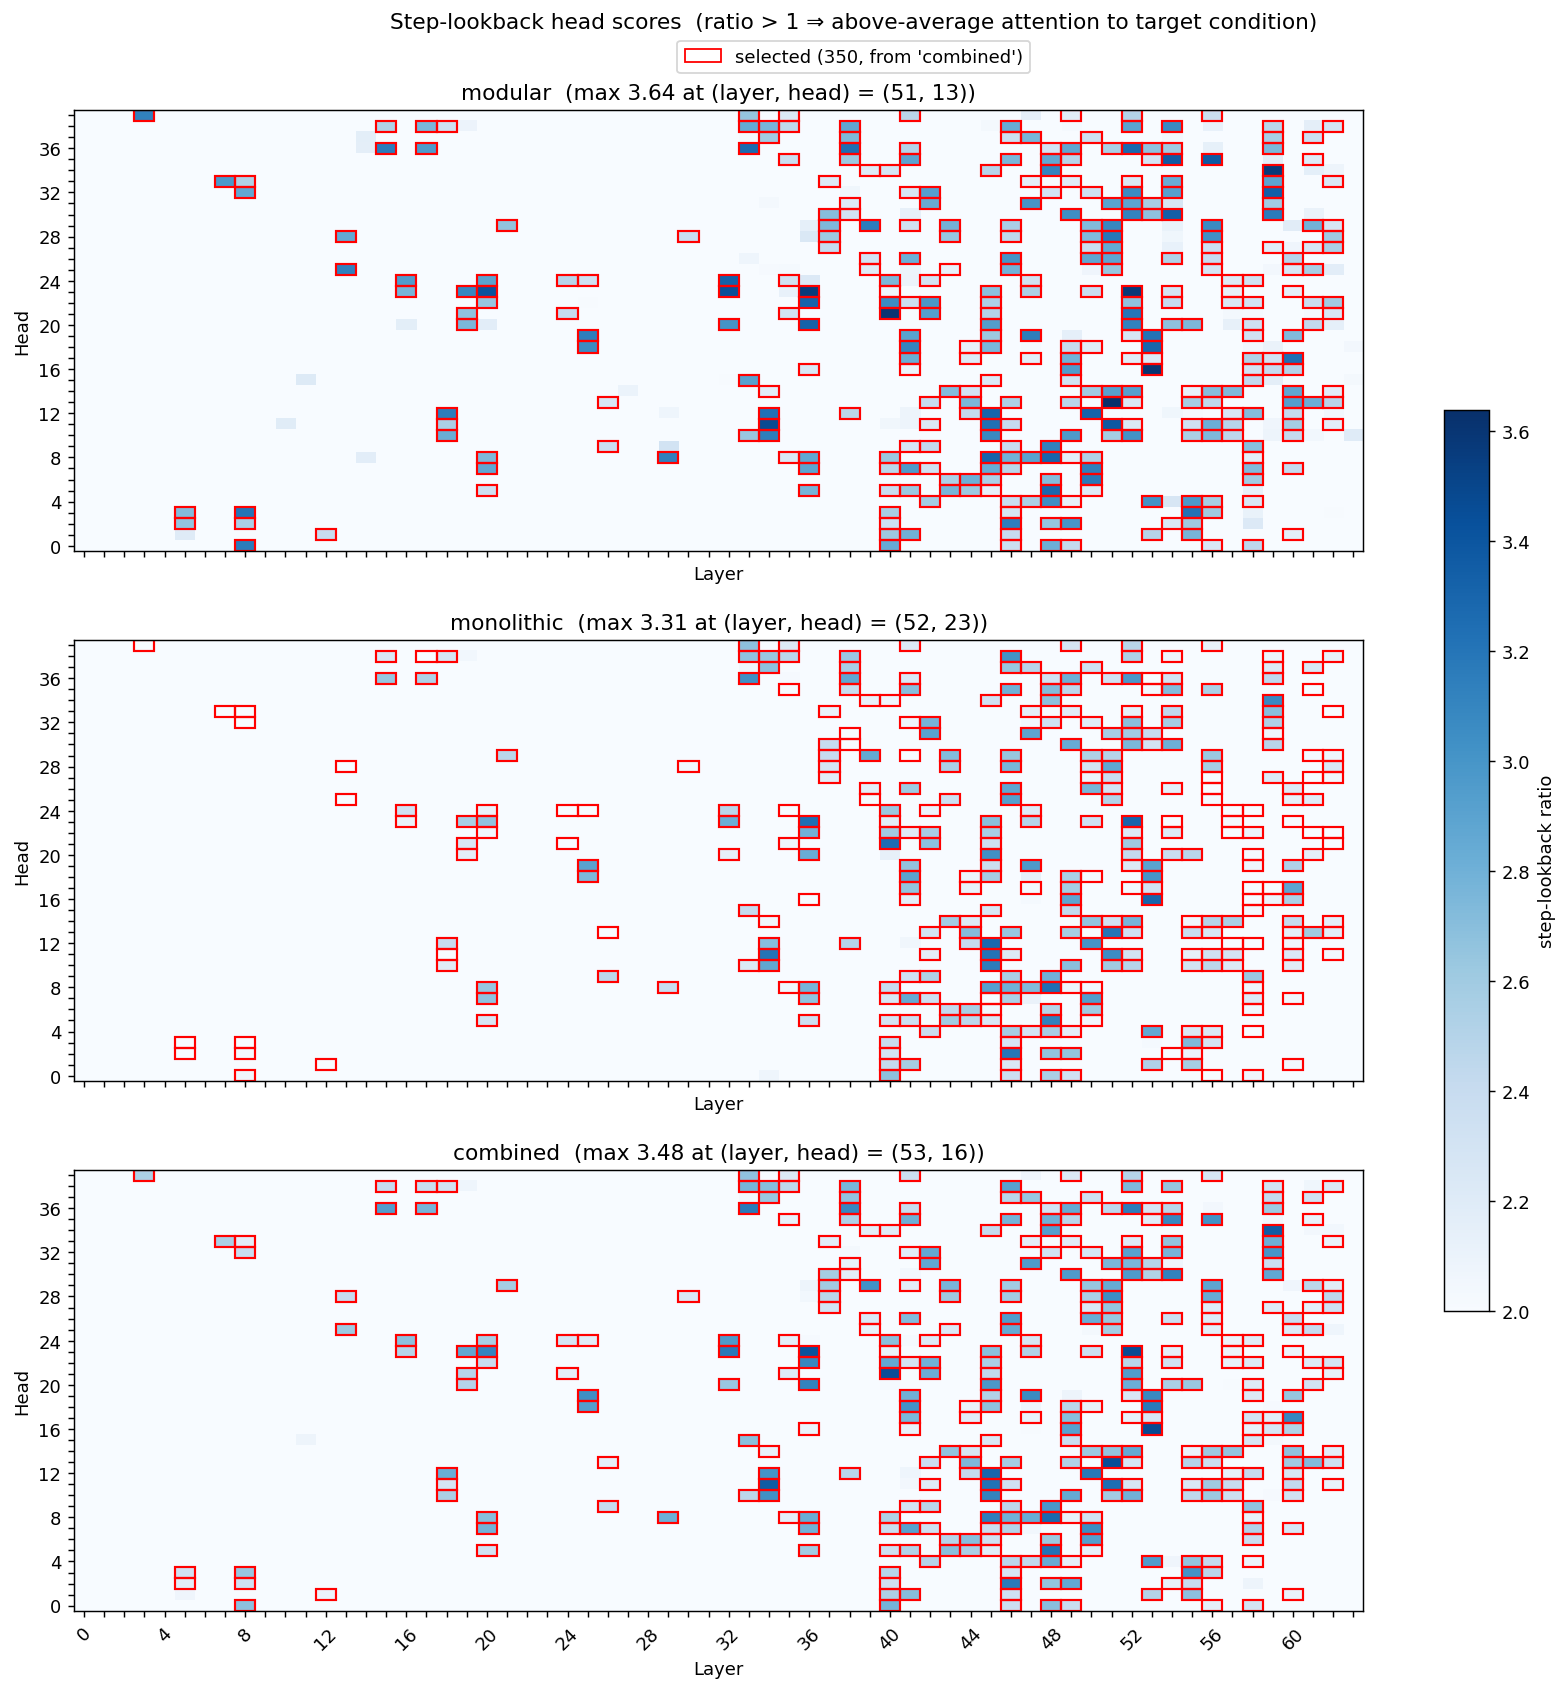

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scripts.clock.score_condition_heads import load_head_scores

# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
# ──────────────────────────────────────────────────────────────────────────────
hs = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)
scores_modular = hs["modular"]            # (n_layers, n_heads)
scores_monolithic = hs["monolithic"]
scores_combined = hs["combined"]
print(f"loaded {hs['dir']}")
print(f"  config: q_span={hs['metadata'].get('q_span')}  compare_with={hs['metadata'].get('compare_with')}")
for name, s in [("modular", scores_modular), ("monolithic", scores_monolithic),
                ("combined", scores_combined)]:
    print(f"  {name:11s} mean={s.mean():.3f}  max={s.max():.3f}")

# ── head selection (overlaid on the heatmaps) ─────────────────────────────────
SELECT_METHOD   = "topk"          # "topk" | "threshold"
TOP_N           = 350              # for topk
THRESHOLD       = 2.8            # for threshold (score ratio)
WHICH_SCORE_NAME = "combined"     # which panel drives selection
WHICH_SCORE = {"modular": scores_modular, "monolithic": scores_monolithic,
               "combined": scores_combined}[WHICH_SCORE_NAME]


def select_heads(score, method="topk", top_n=50, threshold=None):
    """Return [(layer, head), ...] selected from a (n_layers, n_heads) score map."""
    if method == "topk":
        flat = np.argsort(score, axis=None)[::-1][:top_n]
        pairs = (np.unravel_index(i, score.shape) for i in flat)
    elif method == "threshold":
        pairs = zip(*np.where(score >= threshold))
    else:
        raise ValueError(f"unknown method {method!r}")
    return [(int(l), int(h)) for l, h in pairs]


gaze_heads = select_heads(WHICH_SCORE, SELECT_METHOD, TOP_N, THRESHOLD)
print(f"selected {len(gaze_heads)} {len(gaze_heads) / scores_combined.size * 100:.2f}% heads via {SELECT_METHOD} on '{WHICH_SCORE_NAME}'"
      + (f" (top {TOP_N})" if SELECT_METHOD == "topk" else f" (score ≥ {THRESHOLD})"))

panels = [("modular", scores_modular), ("monolithic", scores_monolithic),
          ("combined", scores_combined)]
# vmin = min(s.min() for _, s in panels)
vmin = 2.0
vmax = max(s.max() for _, s in panels)
n_layer_total, n_heads_total = scores_combined.shape

plt.rcParams["figure.dpi"] = 130
def get_ticks(ticks, skip=4):
    return [str(i) if i % skip == 0 else "" for i in ticks]

fig, axes = plt.subplots(len(panels), 1, figsize=(16, 5.0 * len(panels)), sharex=True)
last_im = None
for ax, (title, scores) in zip(axes, panels):
    im = ax.imshow(scores.T, aspect="auto", cmap="Blues", vmin=vmin, vmax=vmax,
                   interpolation="nearest", origin="lower")
    last_im = im
    # outline the selected heads (same set on every panel, from WHICH_SCORE)
    for (l, h) in gaze_heads:
        ax.add_patch(plt.Rectangle((l - 0.5, h - 0.5), 1, 1, linewidth=1.2,
                                   edgecolor="red", facecolor="none"))
    argmax_lh = tuple(int(x) for x in np.unravel_index(scores.argmax(), scores.shape))
    ax.set_title(f"{title}  (max {scores.max():.2f} at (layer, head) = {argmax_lh})")
    ax.set_xlabel("Layer"); ax.set_ylabel("Head")
    ax.set_xticks(range(n_layer_total)); ax.set_xticklabels(get_ticks(range(n_layer_total)), rotation=45)
    ax.set_yticks(range(n_heads_total)); ax.set_yticklabels(get_ticks(range(n_heads_total)))

fig.colorbar(last_im, ax=axes.tolist(), shrink=0.6, label="step-lookback ratio")
sel_handle = mpatches.Patch(edgecolor="red", facecolor="none",
                            label=f"selected ({len(gaze_heads)}, from '{WHICH_SCORE_NAME}')")
fig.legend(handles=[sel_handle], loc="upper center", ncol=1, bbox_to_anchor=(0.5, 0.92))
fig.suptitle("Step-lookback head scores  (ratio > 1 ⇒ above-average attention to target condition)", y=0.93)
plt.show()

In [6]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils

MASK_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt",
)

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        mask.values[0:25] = 0  # zero out early layers
        mask.values[56:] = 0  # zero out late layers
    if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        mask.values[0:18] = 0  # zero out early layers
        mask.values[45:] = 0  # zero out late layers

threshold = 0.9
goalscope_heads = mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(goalscope_heads)}")
print(f"  Selected heads: {goalscope_heads}")

_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    binary_mask.values.zero_()
    for _layer_idx, _head_idx in goalscope_heads:
        binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(
    f"Binary mask: {binary_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * binary_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

Loaded checkpoint from /disk/u/arnab/Codes/Projects/goals/results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 122
  Selected heads: [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29

gaze_heads      :  350  (13.67% of 2560)
goalscope_heads :  122  (4.77%)
overlap         :   44   Jaccard=0.103  | 12.6% of gaze, 36.1% of goalscope


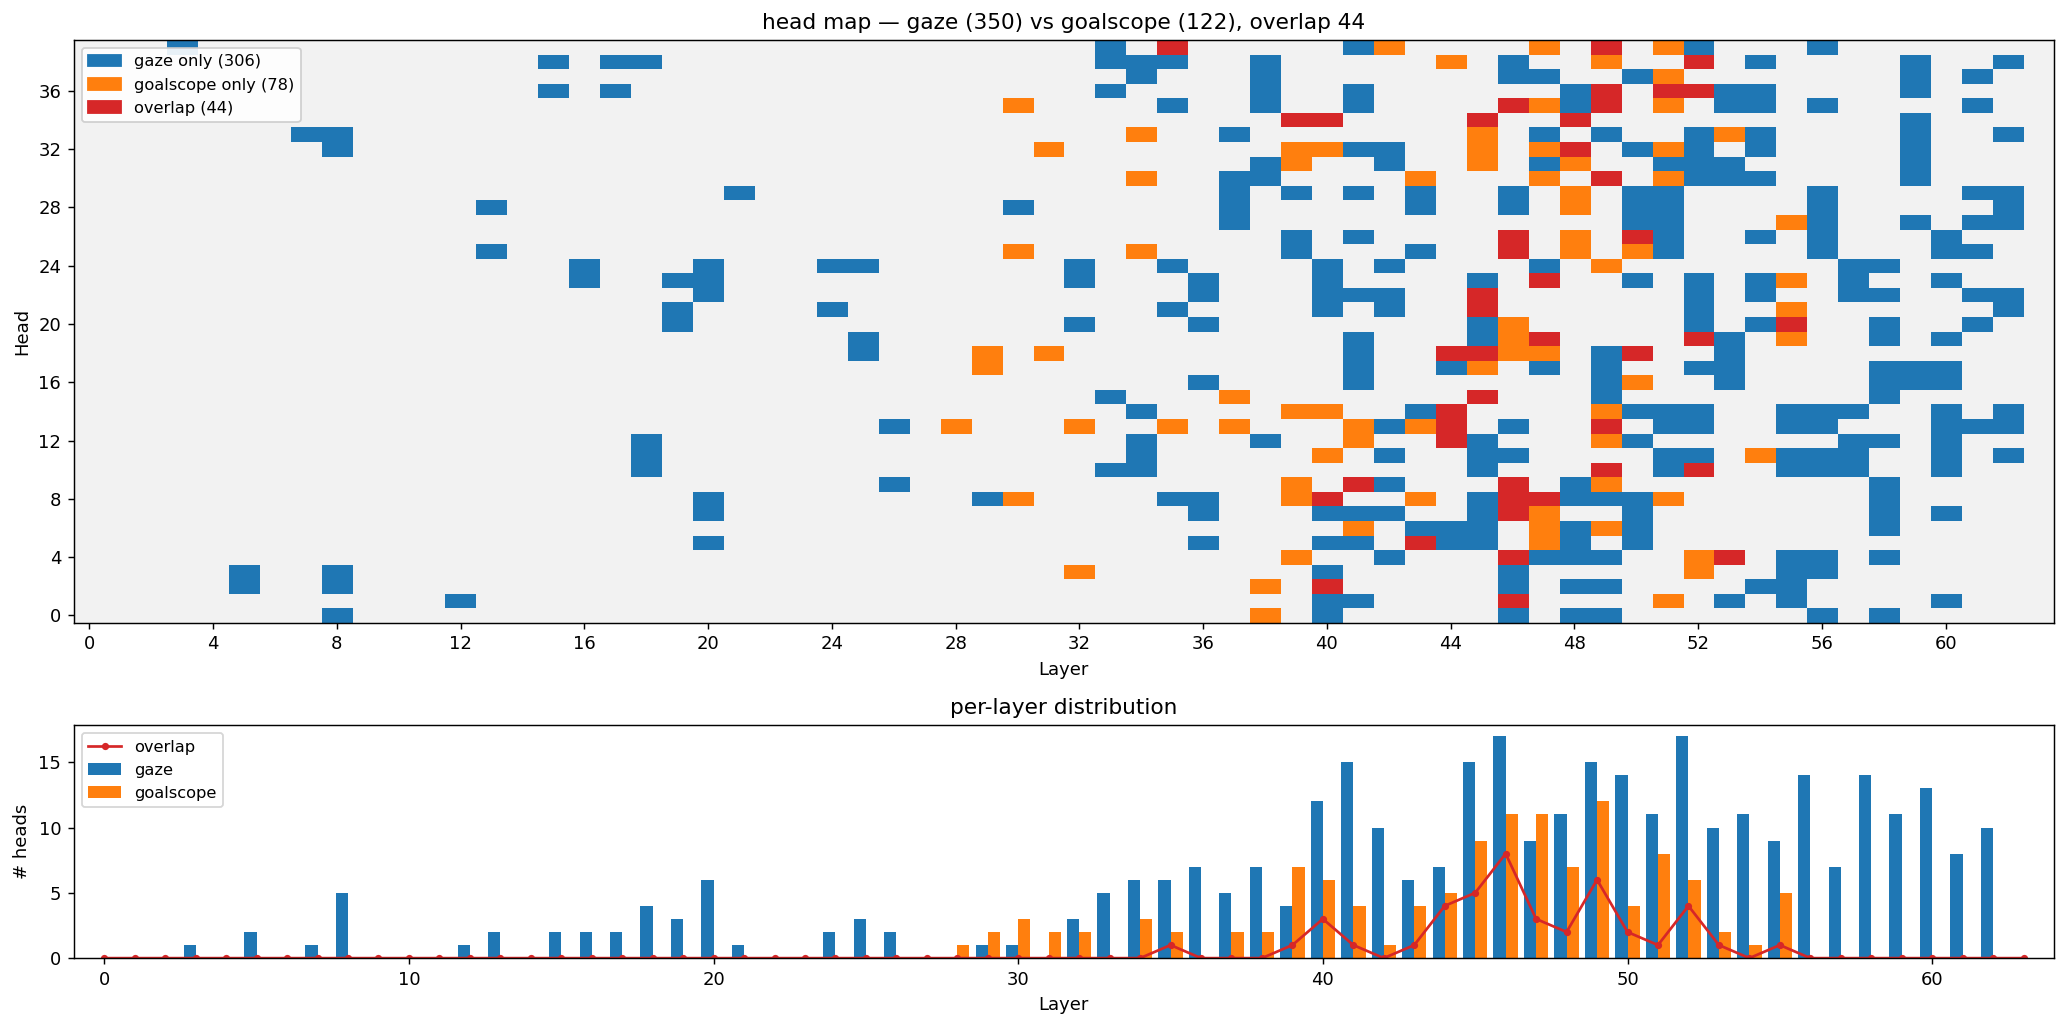

In [7]:
# overlap between gaze_heads (top step-lookback) and goalscope_heads (trained mask)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap, BoundaryNorm

nL, nH = mt.n_layer, mt.model.config.num_attention_heads
gset, oset = set(gaze_heads), set(goalscope_heads)
inter, union = gset & oset, gset | oset

print(f"gaze_heads      : {len(gset):4d}  ({100*len(gset)/(nL*nH):.2f}% of {nL*nH})")
print(f"goalscope_heads : {len(oset):4d}  ({100*len(oset)/(nL*nH):.2f}%)")
print(f"overlap         : {len(inter):4d}   Jaccard={len(inter)/len(union):.3f}  "
      f"| {100*len(inter)/len(gset):.1f}% of gaze, {100*len(inter)/len(oset):.1f}% of goalscope")

# categorical grid: 0 none · 1 gaze-only · 2 goalscope-only · 3 overlap
cat = np.zeros((nL, nH), dtype=int)
for l, h in gset: cat[l, h] |= 1
for l, h in oset: cat[l, h] |= 2
CMAP = ListedColormap(["#f2f2f2", "tab:blue", "tab:orange", "tab:red"])
NORM = BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], CMAP.N)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(16, 8),
                               gridspec_kw={"height_ratios": [3, 1.2]})

ax0.imshow(cat.T, aspect="auto", cmap=CMAP, norm=NORM, origin="lower", interpolation="nearest")
ax0.set_xlabel("Layer"); ax0.set_ylabel("Head")
ax0.set_xticks(range(0, nL, 4)); ax0.set_yticks(range(0, nH, 4))
ax0.set_title(f"head map — gaze ({len(gset)}) vs goalscope ({len(oset)}), overlap {len(inter)}")
ax0.legend(handles=[
    mpatches.Patch(color="tab:blue",   label=f"gaze only ({len(gset - oset)})"),
    mpatches.Patch(color="tab:orange", label=f"goalscope only ({len(oset - gset)})"),
    mpatches.Patch(color="tab:red",    label=f"overlap ({len(inter)})"),
], loc="upper left", framealpha=0.9, fontsize=9)

# per-layer counts
gpl  = np.bincount([l for l, _ in gset],  minlength=nL)
opl  = np.bincount([l for l, _ in oset],  minlength=nL)
ipl  = np.bincount([l for l, _ in inter], minlength=nL)
ax1.bar(np.arange(nL) - 0.2, gpl, width=0.4, color="tab:blue",   label="gaze")
ax1.bar(np.arange(nL) + 0.2, opl, width=0.4, color="tab:orange", label="goalscope")
ax1.plot(np.arange(nL), ipl, "o-", ms=3, color="tab:red", label="overlap")
ax1.set_xlabel("Layer"); ax1.set_ylabel("# heads"); ax1.set_xlim(-1, nL)
ax1.set_title("per-layer distribution"); ax1.legend(fontsize=9)
plt.tight_layout(); plt.show()

In [8]:
from src.attention import AttentionInformation, show_interactive_attention


def load_attn(sample_name, modularity):
    base = os.path.join(CACHE_ROOT, "attn", modularity, sample_name)
    with np.load(os.path.join(base, "attn.npz"), allow_pickle=True) as d:
        attn = d["attn"]            # (n_layers, n_heads, seq, seq) float16, value-weighted
        tokens = list(d["tokens"])
    return attn, tokens


# ── inspect the selected heads (from the heatmap cell) ────────────────────────
ranked = sorted(gaze_heads, key=lambda lh: WHICH_SCORE[lh[0], lh[1]], reverse=True)
print(f"{len(gaze_heads)} selected heads on '{WHICH_SCORE_NAME}':")
for rank, (l, h) in enumerate(ranked[:20], start=1):
    print(f"  {rank:2d}.  L{l:2d} H{h:2d}   score={WHICH_SCORE[l, h]:.3f}")
if len(ranked) > 20:
    print(f"  ... (+ {len(ranked) - 20} more)")

350 selected heads on 'combined':
   1.  L53 H16   score=3.478
   2.  L52 H23   score=3.464
   3.  L40 H21   score=3.452
   4.  L51 H13   score=3.451
   5.  L36 H23   score=3.422
   6.  L59 H34   score=3.364
   7.  L34 H11   score=3.358
   8.  L45 H12   score=3.293
   9.  L48 H 8   score=3.277
  10.  L51 H11   score=3.246
  11.  L45 H11   score=3.222
  12.  L48 H 5   score=3.217
  13.  L50 H12   score=3.181
  14.  L32 H23   score=3.175
  15.  L53 H18   score=3.168
  16.  L33 H36   score=3.167
  17.  L46 H 2   score=3.166
  18.  L52 H36   score=3.150
  19.  L45 H 8   score=3.143
  20.  L54 H30   score=3.113
  ... (+ 330 more)


In [9]:
# scores = WHICH_SCORE.reshape(WHICH_SCORE.shape[0] * WHICH_SCORE.shape[1])
# scores = sorted(scores, reverse=True)

# plt.plot(scores[:50])

In [10]:
### ---- demo sample for the attention viz ----
VIZ_SAMPLE = DEMO_SAMPLE
VIZ_MODULARITY = DEMO_MODULARITY
### -----------------------------------------
attn_arr, tokens = load_attn(VIZ_SAMPLE, VIZ_MODULARITY)
print(f"{VIZ_SAMPLE} · {VIZ_MODULARITY}:  attn {attn_arr.shape} dtype={attn_arr.dtype}  ({len(tokens)} tokens)")
attn_info = AttentionInformation(tokenized_prompt=tokens, attention_matrices=attn_arr)

# Skip the chat-template prefix so the viz starts at the user query.
start_from = 0
try:
    first_user = next(i for i, t in enumerate(tokens) if "user" in t.replace("＜", "<"))
    start_from = max(0, first_user - 1)
except StopIteration:
    pass

# selected_heads = sorted(goalscope_heads)  # or gaze_heads
selected_heads = sorted(gaze_heads)  # or goalscope_heads
show_interactive_attention(
    attn_info=attn_info,
    selected_heads=selected_heads,
    start_from=start_from,
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    title=f"{VIZ_SAMPLE} · {VIZ_MODULARITY} · {len(selected_heads)} selected heads (value-weighted)",
    height=None,
)

cond_0015 · monolithic:  attn (64, 40, 312, 312) dtype=float16  (312 tokens)


'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>cond_0015 · monolithic · 350 selected heads (value-weighted)</title>\n<style>\n #iaviz-86815f09 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-86815f09 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-86815f09 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-86815f09 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-86815f09 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-86815f09 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   mar

In [11]:
# from src.attention import get_attention_matrices

# lbl, comp = load_labeled(VIZ_SAMPLE, VIZ_MODULARITY)
# print(comp.keys())
# test_prompt = comp["prompt"] + comp["generation"]

# updated_attn_info = get_attention_matrices(
#     input = test_prompt,
#     mt = mt,
#     value_weighted = False,
# )

# show_interactive_attention(
#     attn_info=updated_attn_info,
#     selected_heads=selected_heads,
#     start_from=start_from,
#     agg="mean",
#     normalize="row_max",
#     cmap="Blues",
#     title=f"{VIZ_SAMPLE} · {VIZ_MODULARITY} · {len(selected_heads)} selected heads (live generation)",
#     height=None,
# )

## 3. Run a few live generations

Load the `ConditionDataset` and generate greedy completions with the full model —
the same prompt construction the build script uses.

In [12]:
from src.goals.condition_data import ConditionDataset
from src.goals.functional import apply_chat_template, supports_chat_template
from src.tokens import prepare_input
from src.functional import generate_with_patch

DATASET_PATH = os.path.join(
    env_utils.DEFAULT_DATA_DIR, "multistep", "condition_check_python.json"
)
cond_ds = ConditionDataset.load(DATASET_PATH)
print(f"loaded {len(cond_ds.samples)} samples from {DATASET_PATH}")
sample = cond_ds.samples[0]
sample.modularity = DEMO_MODULARITY  # override for viz demo

def build_prompt(sample):
    instr = sample.render_instruction()
    stub = sample.render_code_stub()
    if supports_chat_template(mt):
        return apply_chat_template(
            mt=mt, user_query=instr.strip(), incomplete_code=stub
        )
    return instr + "\nAnswer:\n" + stub


test_prompt = build_prompt(sample)
code_prefix = """    a = n >= 40
"""
test_prompt += code_prefix

print(test_prompt)

# correct_impl = """bool isPalindrome(string s) {
#     int left = 0, right = s.size() - 1;
#     while (left < right) {
#         if (s[left] != s[right]) return false;
#         left++; right--;
#     }
#     return true;
# }
# """

# incorrect_impl = """bool isPalindrome(string s) {
#     return s == s[::-1];
# }
# """

# # suffix = "</code>\n\n"
# suffix = ""

# messages = [
#     {
#         "role": "system",
#         "content": "You are a helpful assistant proficient in coding.",
#     },
#     {
#         "role": "user",
#         "content": "Write a C++ function that checks if a string is a palindrome. Just the code, no explanations and comments. Make sure that your code in always inside <code> </code> markers.",
#     },
#     {
#         "role": "assistant",
#         "content": f"<code>\n{incorrect_impl}{suffix}",
#     },
# ]

# test_prompt = mt.tokenizer.apply_chat_template(
#     messages,
#     add_generation_prompt=False,  # Don't add a new assistant header
#     continue_final_message=True,  # Don't close the assistant turn with <|eot_id|>
#     tokenize=False,
#     chat_template_kwargs={"enable_thinking": False},  # only Qwen3 and Qwen3.5
# )

test_gen = generate_with_patch(
    mt=mt,
    inputs=test_prompt,
    max_new_tokens=128,
    do_sample=False,
    remove_prefix=True,
    n_gen_per_prompt=1,
)[0]

rich_print(f"[white]{test_prompt}[white][sea_green1]{test_gen}[sea_green1]")

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


loaded 1000 samples from /disk/u/arnab/Codes/Projects/goals/data/multistep/condition_check_python.json
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is less than or equal to 500
2. n is positive
3. n is a perfect square
4. n is between 10 and 200 (inclusive)

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condit

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is less than or equal to 500
2. n is positive
3. n is a perfect square
4. n is between 10 and 200 (inclusive)

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = n >= 40
    b = n > 0
    c = int(n**0.5)**2 == n
    d = 10 <= n <= 200
    print(f"a: {a}, b: {b}, c: {c}, d: {d}, all: {a and b and c and d}")
</code>

In [13]:
from src.attention import get_attention_matrices

full_prompt = test_prompt + test_gen
test_attn_info = get_attention_matrices(
    input = full_prompt,
    mt = mt,
    value_weighted = True,
)
show_interactive_attention(
    attn_info=test_attn_info,
    selected_heads=sorted(gaze_heads),
    start_from=0,
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    title=f"Live generation attention — {len(gaze_heads)} selected heads",
    height=None,
)

'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>Live generation attention — 350 selected heads</title>\n<style>\n #iaviz-cc1f4fe4 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-cc1f4fe4 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-cc1f4fe4 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-cc1f4fe4 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-cc1f4fe4 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-cc1f4fe4 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   margin: 1px 0;\n 

In [14]:
# # Pick a sample and generate.
# s = cond_ds.samples[5]
# print(f"{s.name}  lang={s.lang}  modularity={s.modularity}  ({s.spec.num_conditions} conditions)\n")
# prompt = build_prompt(s)
# gen = generate(prompt, max_new_tokens=512)
# print(gen)

## 4. Causal test — restrict the gaze heads to one step's spec

Sufficiency test for the gaze→implement chain. At `b = ` (where the LM normally
implements **condition `CURRENT_STEP`**), restrict *only the selected gaze heads*
(query rows ≥ `q_start`) so that — across the whole context — they may attend to
**nothing but cond `TARGET_STEP`'s spec span**. Everything else (the other specs,
the instruction, the code, the sink) gets `−∞`; softmax renormalizes over the
target span, so the LM itself sets the weights *within* it (no fabricated scores).

Setting: **monolithic** (the inline RHS encodes the predicate, so gaze is
load-bearing). Readout: eyeball the generated `b`-RHS against the spec lines.

Findings so far (`cond_0001`, b→cond2): the redirect only bites once ~`N_GAZE≈300`
heads (~12%) are restricted — the signal is **distributed**, not a sparse set —
and **matched-count random heads produce no change**, so the effect is
gaze-specific, not generic content-injection. Requires `selected_heads` from §2
(set §2 `TOP_N ≥ N_GAZE`).

In [15]:
import re
import random as _random
from collections import defaultdict

import torch
from src.functional import get_module_nnsight
from src.tokens import prepare_input

N_HEADS = mt.model.config.num_attention_heads


def group_heads(heads):
    d = defaultdict(list)
    for l, h in sorted(heads):                  # ascending layer = nnsight execution order
        d[l].append(h)
    return dict(d)


def random_heads_like(selected, seed=0):
    rng = _random.Random(seed)
    sel = set(selected)
    pool = [(l, h) for l in range(mt.n_layer) for h in range(N_HEADS) if (l, h) not in sel]
    return rng.sample(pool, len(selected))


def spec_line_spans(lab):
    """Full numbered spec-line token span per condition (prompt_token_range), or None."""
    return [tuple(sl.prompt_token_range) if sl.prompt_token_range else None for sl in lab.labels]


def cut_after_assignment(generation, var):
    m = re.search(rf"(?m)^\s*{re.escape(var)}\s*=", generation)
    if m is None:
        raise ValueError(f"no '{var} =' assignment line found in generation")
    return m.end()


def keys_outside_span(span, seq):
    """All key indices NOT in `span` — i.e. mask everything except `span`."""
    keep = set(range(span[0], span[1]))
    return [k for k in range(seq) if k not in keep]


@torch.no_grad()
def generate_with_head_attn_mask(prefill, layer_to_heads, masked_keys, q_start, max_new=30):
    """Greedy non-cached decode. For each layer→[heads], add −∞ to the pre-softmax
    attention scores at query rows ≥ q_start over key positions `masked_keys`, for
    those heads only. layer_to_heads={} ⇒ unmodified baseline."""
    ids = prepare_input(prompts=[prefill], tokenizer=mt, add_special_tokens=False)["input_ids"]
    mk = torch.tensor(sorted(masked_keys), dtype=torch.long)
    gen = []
    for _ in range(max_new):
        seq = ids.shape[1]
        kvec = torch.zeros(seq)
        if mk.numel():
            kvec[mk] = float("-inf")
        with mt.trace({"input_ids": ids, "attention_mask": torch.ones_like(ids)},
                      scan=False, validate=False):
            for L in sorted(layer_to_heads):            # ascending = nnsight execution order
                am = get_module_nnsight(mt, mt.attn_module_name_format.format(L))
                sm = am.source.attention_interface_0.source.nn_functional_softmax_0
                km = torch.zeros(1, N_HEADS, seq, seq)
                for h in layer_to_heads[L]:
                    km[0, h, q_start:, :] += kvec
                sm.input = sm.input + km.to(device=sm.input.device, dtype=sm.input.dtype)
            logits = mt.output.logits[:, -1, :].save()
        nxt = int(logits[0].argmax(-1))
        if nxt == mt.tokenizer.eos_token_id:
            break
        gen.append(nxt)
        ids = torch.cat([ids, torch.tensor([[nxt]], device=ids.device)], dim=1)
    return mt.tokenizer.decode(gen, skip_special_tokens=True)

In [16]:
len(selected_heads)

350

In [17]:
from rich.markup import escape

### ---- restrict-to-target demo (monolithic) ----
RDX_SAMPLE = "cond_0015"     # monolithic sample with ≥3 distinct-predicate conditions
ASSIGN_VAR = "b"             # assignment we intervene at  (a=cond0, b=cond1, c=cond2, …)
TARGET_STEP = 2              # restrict the gaze to this condition's spec span
N_GAZE = 300                 # # of top gaze heads to restrict (needs §2 TOP_N ≥ N_GAZE)
MAX_NEW = 30
### -----------------------------------------------
CURRENT_STEP = ord(ASSIGN_VAR) - ord("a")
gaze = gaze_heads[:N_GAZE]
# gaze = goalscope_heads

lab, comp = load_labeled(RDX_SAMPLE, "monolithic")
spans = spec_line_spans(lab)
cut = cut_after_assignment(lab.generation, ASSIGN_VAR)
prefill = lab.full_prompt + lab.generation[:cut]

rich_print(f"[white]{prefill}[/white]")

ids = prepare_input(prompts=[prefill], tokenizer=mt, add_special_tokens=False)["input_ids"]
seq = ids.shape[1]
q_start = seq - 1                          # last prefill token writes the first RHS token
target_span = spans[TARGET_STEP]
restrict_mask = keys_outside_span(target_span, seq)

l2h = group_heads(gaze)
r2h = group_heads(random_heads_like(gaze, seed=0))

rich_print(f"[demo config] sample={RDX_SAMPLE}  assign_var='{ASSIGN_VAR}'  N_GAZE={len(gaze)}")
print(f"restrict gaze → cond {TARGET_STEP} span {tuple(target_span)} = "
      f"{mt.tokenizer.decode(ids[0, target_span[0]:target_span[1]])!r}\n")
for i, sl in enumerate(lab.labels):
    tag = "  ← TARGET" if i == TARGET_STEP else ("  ← current" if i == CURRENT_STEP else "")
    print(f"  cond {i}: {sl.step_text}{tag}")
print(f"\nnatural cached b-line:  {lab.generation[cut:cut+70].splitlines()[0]!r}")

base  = generate_with_head_attn_mask(prefill, {},  restrict_mask, q_start, MAX_NEW)
rich_print(f"\n[baseline   no mask        ]  {ASSIGN_VAR} =[sea_green1]{escape(base)}[/]")
restr = generate_with_head_attn_mask(prefill, l2h, restrict_mask, q_start, MAX_NEW)
rich_print(f"[restrict   gaze⊂cond{TARGET_STEP}     ]  {ASSIGN_VAR} =[salmon1]{escape(restr)}[/]")
ctrl  = generate_with_head_attn_mask(prefill, r2h, restrict_mask, q_start, MAX_NEW)
rich_print(f"[control    {len(gaze)} random heads]  {ASSIGN_VAR} =[plum1]{escape(ctrl)}[/]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. the sum of n's digits is greater than 20
2. n is positive
3. n is between 50 and 100 (inclusive)

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = sum(int(digit) for digit in str(n)) > 20
    b =

sample=cond_0015  assign_var='b'  N_GAZE=300

restrict gaze → cond 2 span (91, 105) = ' n is between 50 and 100 (inclusive)\n\n'

  cond 0: the sum of n's digits is greater than 20
  cond 1: n is positive  ← current
  cond 2: n is between 50 and 100 (inclusive)  ← TARGET

natural cached b-line:  ' n > 0'


b = n > 0
    c = 50 <= n <= 100
    print(f"Condition 1: {a},

b = n >= 50
    c = n <= 100
    print(f"Condition 1: {b}, Condition 2

b = n > 0
    c = 50 <= n <= 100
    print(f"Condition 1: {a},

In [18]:
# ### ---- directionality sweep: restrict the gaze to each step in turn ----
# # Strongest evidence: the LM implements *whichever* step we restrict the gaze to.
# rich_print(f"sample {RDX_SAMPLE} · '{ASSIGN_VAR} =' (natural = cond {CURRENT_STEP}) · "
#            f"restrict {len(gaze)} gaze heads →")
# for t in range(len(lab.labels)):
#     if spans[t] is None:
#         continue
#     mask_t = keys_outside_span(spans[t], seq)
#     out = generate_with_head_attn_mask(prefill, l2h, mask_t, q_start, MAX_NEW)
#     mark = "  (natural)" if t == CURRENT_STEP else ""
#     rich_print(f"  gaze⊂cond {t} ({lab.labels[t].step_text[:34]:34s}){mark}:  "
#                f"{ASSIGN_VAR} =[grey70]{escape(out)!r}[/]")

## 2b. Gaze-attractor score per instruction span

Hypothesis: while the LM is mid-way through implementing condition *i*, its query tokens have a higher **gaze-attractor** score toward condition *i*'s `id_substrs` key tokens than toward the other conditions'. The keys are fixed (K-projection of the spec tokens); only the query's Q-projection decides where to read — so the score isolates the query side.

Per gaze head `(ℓ,h)`: take per-head `q` at each generated token and `k` at condition *i*'s `id_substrs` positions (same layer ℓ), score `q·k/√d` (knob `NORMALIZE=True` → cosine), **mean over the span's keys** (length-normalized), then **mean over gaze heads**. `INCLUDE_ROPE` toggles the rotary rotation (off = pure content affinity). A dashed baseline = mean score to non-`id_substr` prompt tokens. Key ranges are the precomputed `step_key_token_ranges` (same source the scorer uses).

In [19]:
import torch
from src.functional import get_module_nnsight
from src.tokens import prepare_input

CFG       = mt.model.config
N_Q       = CFG.num_attention_heads
N_KV      = getattr(CFG, "num_key_value_heads", N_Q)
HEAD_DIM  = getattr(CFG, "head_dim", CFG.hidden_size // N_Q)
GQA_GROUP = N_Q // N_KV                     # query heads per kv head
print(f"N_Q={N_Q}  N_KV={N_KV}  HEAD_DIM={HEAD_DIM}  GQA_GROUP={GQA_GROUP}")


def load_key_ranges(sample_name, modularity):
    """Precomputed per-condition id_substr token ranges (the scorer's keys)."""
    p = os.path.join(CACHE_ROOT, modularity, sample_name, "key_ranges.json")
    with open(p) as f:
        return json.load(f)["step_key_token_ranges"]      # list[cond][substr][2]


def _flat_key_idx(step_ranges, seq):
    idx = []
    for a, b in step_ranges:
        idx += [t for t in range(a, b) if 0 <= t < seq]
    return sorted(set(idx))


def _maybe_rope(q, k, include_rope):
    """q (seq,N_Q,D), k (seq,N_KV,D). Apply the model's rotary if requested."""
    if not include_rope:
        return q, k
    from transformers.models.qwen2.modeling_qwen2 import apply_rotary_pos_emb
    dev = next(mt.model.parameters()).device
    seq = q.shape[0]
    pos = torch.arange(seq, device=dev).unsqueeze(0)
    qd = q.permute(1, 0, 2).unsqueeze(0).to(dev)     # (1,N_Q,seq,D)
    kd = k.permute(1, 0, 2).unsqueeze(0).to(dev)     # (1,N_KV,seq,D)
    cos, sin = mt.model.model.rotary_emb(qd, pos)
    qd, kd = apply_rotary_pos_emb(qd, kd, cos, sin)
    return qd[0].permute(1, 0, 2).float().cpu(), kd[0].permute(1, 0, 2).float().cpu()


@torch.no_grad()
def _capture_qk(inp, layers):
    """One forward; per-head q,k states for `layers`. {l: (q(seq,N_Q,D), k(seq,N_KV,D))}."""
    cap = {}
    with mt.trace({"input_ids": inp["input_ids"], "attention_mask": inp["attention_mask"]},
                  scan=False, validate=False):
        for l in layers:
            base = mt.attn_module_name_format.format(l)
            cap[(l, "q")] = get_module_nnsight(mt, base + ".q_proj").output.save()
            cap[(l, "k")] = get_module_nnsight(mt, base + ".k_proj").output.save()
    out = {}
    for l in layers:
        q = cap[(l, "q")][0].detach().float().cpu().view(-1, N_Q, HEAD_DIM)
        k = cap[(l, "k")][0].detach().float().cpu().view(-1, N_KV, HEAD_DIM)
        out[l] = (q, k)
    return out


@torch.no_grad()
def gaze_attractor(lab, sample_name, modularity, gaze_heads, normalize=True, include_rope=False):
    """Per-condition gaze-attractor score at every generated token, averaged over heads.
    normalize=True -> cosine; normalize=False -> raw dot product (no 1/sqrt(d))."""
    combined = lab.full_prompt + lab.generation
    inp = prepare_input(prompts=[combined], tokenizer=mt, add_special_tokens=False)
    seq = inp["input_ids"].shape[1]
    enc = tok(combined, return_offsets_mapping=True, add_special_tokens=False)
    assert len(enc["input_ids"]) == seq, (len(enc["input_ids"]), seq)   # range alignment
    char_off = len(lab.full_prompt)
    gen_start = next(j for j, (a, b) in enumerate(enc["offset_mapping"]) if a >= char_off and b > a)
    q_pos = list(range(gen_start, seq))
    gen_tokens = [tok.decode([enc["input_ids"][p]]) for p in q_pos]

    kr = load_key_ranges(sample_name, modularity)
    n_cond = min(len(lab.labels), len(kr))
    cond_keys = {i: _flat_key_idx(kr[i], seq) for i in range(n_cond)}
    used = set().union(*[set(v) for v in cond_keys.values()]) if cond_keys else set()
    base_keys = [k for k in range(gen_start) if k not in used]   # non-id prompt tokens

    layers = sorted({l for l, _ in gaze_heads})
    qk = {l: _maybe_rope(q, k, include_rope) for l, (q, k) in _capture_qk(inp, layers).items()}

    Q = len(q_pos)
    acc = {i: np.zeros(Q) for i in range(n_cond)}
    acc_base = np.zeros(Q)
    for (l, h) in gaze_heads:
        q, k = qk[l]
        qh = q[q_pos][:, h, :]                       # (Q, D)
        kk = k[:, h // GQA_GROUP, :]                 # (seq, D) — GQA: head's kv group
        if normalize:
            qh = qh / (qh.norm(dim=-1, keepdim=True) + 1e-8)
            kk = kk / (kk.norm(dim=-1, keepdim=True) + 1e-8)
        aff = (qh @ kk.T).numpy()                    # cosine if normalized, else raw dot
        for i in range(n_cond):
            if cond_keys[i]:
                acc[i] += aff[:, cond_keys[i]].mean(axis=1)
        if base_keys:
            acc_base += aff[:, base_keys].mean(axis=1)
    H = max(len(gaze_heads), 1)
    for i in acc:
        acc[i] /= H
    acc_base /= H
    return dict(q_pos=q_pos, gen_start=gen_start, n_cond=n_cond, gen_tokens=gen_tokens,
                scores=acc, baseline=acc_base, cond_keys=cond_keys)

N_Q=40  N_KV=8  HEAD_DIM=128  GQA_GROUP=5


cond_0015 · monolithic: 3 conditions, 78 generated tokens, 20 gaze heads


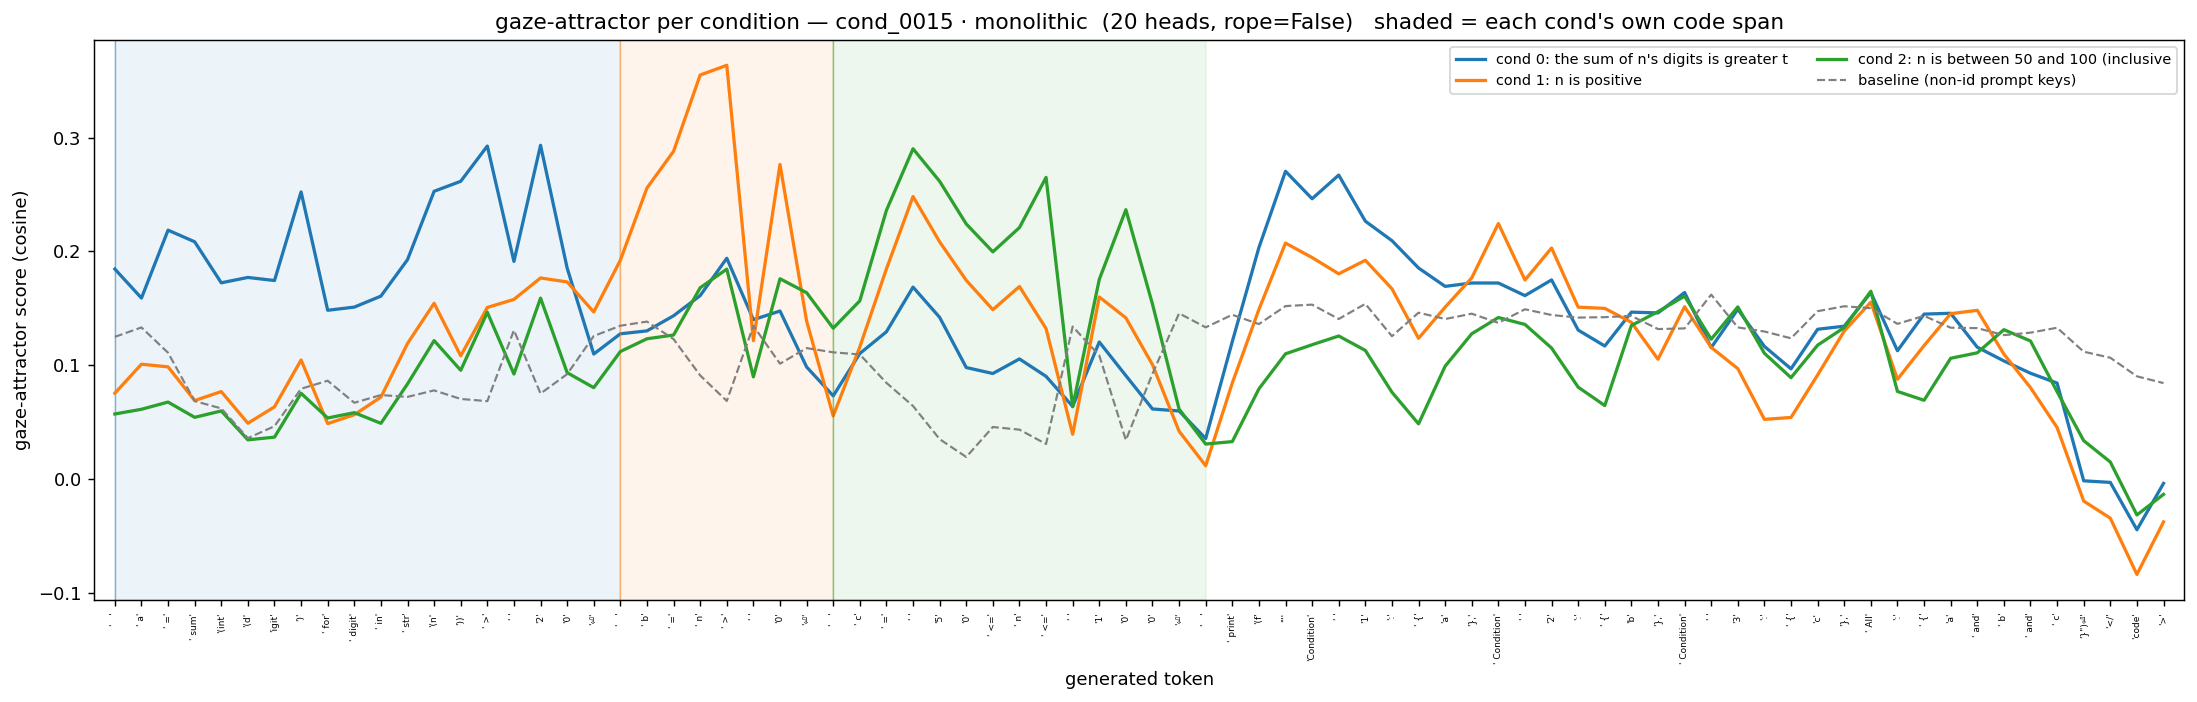

In [20]:
### ---- gaze-attractor config ----
GAZE_SAMPLE     = DEMO_SAMPLE
GAZE_MODULARITY = DEMO_MODULARITY
NORMALIZE       = True              # True -> cosine ; False -> raw scaled dot
INCLUDE_ROPE    = False             # apply rotary to q,k before affinity
GAZE_N          = 20   # use the top-N gaze heads from §2
### --------------------------------
lab_g, comp_g = load_labeled(GAZE_SAMPLE, GAZE_MODULARITY)
res = gaze_attractor(lab_g, GAZE_SAMPLE, GAZE_MODULARITY, gaze_heads[:GAZE_N], NORMALIZE, INCLUDE_ROPE)
print(f"{GAZE_SAMPLE} · {GAZE_MODULARITY}: {res['n_cond']} conditions, "
      f"{len(res['q_pos'])} generated tokens, {GAZE_N} gaze heads")

cmap = plt.get_cmap("tab10")
x = np.arange(len(res["q_pos"]))                  # generated-token index (gen-relative)
gen_start = res["gen_start"]

fig, ax = plt.subplots(figsize=(17, 5.5))
for i in range(res["n_cond"]):
    col = cmap(i % 10)
    ax.plot(x, res["scores"][i], lw=1.8, color=col,
            label=f"cond {i}: {lab_g.labels[i].step_text[:34]}")
    sl = lab_g.labels[i]
    if sl.gen_token_range:                        # shade this cond's own code segment
        a = sl.gen_token_range[0] - gen_start
        b = sl.gen_token_range[1] - gen_start
        ax.axvspan(a, b, color=col, alpha=0.08)
        ax.axvline(a, color=col, lw=0.8, alpha=0.5)
ax.plot(x, res["baseline"], lw=1.2, ls="--", color="gray", label="baseline (non-id prompt keys)")
_vis_tok = lambda t: t.replace("\n", "\u23ce").replace("\t", "\u21e5")
ax.set_xticks(x)
ax.set_xticklabels([f"{_vis_tok(t)!r}" for t in res["gen_tokens"]], rotation=90, fontsize=5)
ax.set_xlabel("generated token")
ax.set_ylabel("gaze-attractor score " + ("(cosine)" if NORMALIZE else "(scaled dot)"))
ax.set_title(f"gaze-attractor per condition — {GAZE_SAMPLE} · {GAZE_MODULARITY}  "
             f"({GAZE_N} heads, rope={INCLUDE_ROPE})   shaded = each cond's own code span")
ax.legend(fontsize=8, ncol=2, loc="upper right")
ax.margins(x=0.01)
plt.tight_layout()
plt.show()

### aggregate across samples — bucketed by generation span

The generation has **4 spans**: the 3 condition code segments + (print + rest). Split each span into `NUM_BUCKETS` roughly-equal buckets (`np.array_split`); a bucket's score for instruction span *j* = mean gaze-attractor score over the query tokens in that bucket toward condition *j*'s `id_substrs`. This gives a fixed-width x-axis (4×`NUM_BUCKETS`) so different-length samples become averageable while keeping the per-query-token view (coarsened). **Hypothesis:** inside cond-*i*'s buckets the span-*i* line leads. `NORM_MODE` (per query token): `diff` = `score − baseline` (default), `ratio`, or `none`. Compute and viz are in separate cells.

In [22]:
import random as _random
from tqdm.auto import tqdm

### ---- bucketed aggregation config ----
AGG_MODULARITY = "monolithic"    # 'modular' | 'monolithic'
AGG_N_COND     = 3                  # keep only samples with exactly this many conditions
AGG_N_SAMPLES  = 10                 # cap on samples actually used
AGG_NORMALIZE  = True               # True -> cosine ; False -> raw dot
AGG_ROPE       = False
NORM_MODE      = "diff"             # 'diff' | 'ratio' | 'none'  (per query token)
NUM_BUCKETS    = 8
AGG_GAZE_N     = len(gaze_heads)
AGG_SEED       = 0
### --------------------------------------
N_QSPAN = AGG_N_COND + 1                                   # 3 cond spans + print/rest
QSPAN_LABELS = [f"cond {i}" for i in range(AGG_N_COND)] + ["print/rest"]


def list_condition_samples(modularity):
    d = os.path.join(CACHE_ROOT, modularity)
    out = []
    for s in sorted(os.listdir(d)):
        sd = os.path.join(d, s)
        if os.path.isdir(sd) and os.path.exists(os.path.join(sd, "labels.json")) \
                and os.path.exists(os.path.join(sd, "key_ranges.json")):
            out.append(s)
    return out


def _normalize(arr, base, mode):
    if mode == "ratio":
        return arr / (base + 1e-8)
    if mode == "diff":
        return arr - base
    return arr


def _gen_span_bounds(lab, gen_start, L, n_cond):
    """Local [a,b) into q_pos for the 3 condition code spans + (print + rest)."""
    bounds = [(lab.labels[i].gen_token_range[0] - gen_start,
               lab.labels[i].gen_token_range[1] - gen_start) for i in range(n_cond)]
    bounds.append((lab.labels[n_cond - 1].gen_token_range[1] - gen_start, L))   # print + rest
    return bounds


def _bucket_means(vec, span, num_buckets):
    a, b = max(span[0], 0), min(span[1], len(vec))
    if b <= a:
        return [np.nan] * num_buckets
    return [vec[ix].mean() if len(ix) else np.nan
            for ix in np.array_split(np.arange(a, b), num_buckets)]


def build_buckets(modularity, n_cond, n_samples, normalize, include_rope,
                  norm_mode, num_buckets, gaze, seed=0):
    cands = list_condition_samples(modularity)
    _random.Random(seed).shuffle(cands)
    stacks, bases, used = [], [], []
    for s in tqdm(cands):
        if len(stacks) >= n_samples:
            break
        lab, _ = load_labeled(s, modularity)
        if len(lab.labels) != n_cond:
            continue
        if any(lab.labels[i].gen_token_range is None for i in range(n_cond)):
            continue
        res = gaze_attractor(lab, s, modularity, gaze, normalize, include_rope)
        if res["n_cond"] != n_cond:
            continue
        gs, L, base = res["gen_start"], len(res["q_pos"]), res["baseline"]
        norm_scores = {j: _normalize(res["scores"][j], base, norm_mode) for j in range(n_cond)}
        bounds = _gen_span_bounds(lab, gs, L, n_cond)
        B = np.full((len(bounds) * num_buckets, n_cond), np.nan)
        Bbase = np.full(len(bounds) * num_buckets, np.nan)
        for qs, span in enumerate(bounds):
            sl = slice(qs * num_buckets, (qs + 1) * num_buckets)
            for j in range(n_cond):
                B[sl, j] = _bucket_means(norm_scores[j], span, num_buckets)
            Bbase[sl] = _bucket_means(base, span, num_buckets)
        stacks.append(B); bases.append(Bbase); used.append(s)
    return np.stack(stacks), np.stack(bases), used


BK_STACK, BK_BASE, BK_USED = build_buckets(
    AGG_MODULARITY, AGG_N_COND, AGG_N_SAMPLES, AGG_NORMALIZE, AGG_ROPE,
    NORM_MODE, NUM_BUCKETS, gaze_heads[:AGG_GAZE_N], AGG_SEED)
print(f"buckets {BK_STACK.shape}  (N, {N_QSPAN}\u00d7{NUM_BUCKETS} buckets, {AGG_N_COND} spans) "
      f"from {len(BK_USED)} samples")

  0%|          | 0/500 [00:00<?, ?it/s]

KeyboardInterrupt: 

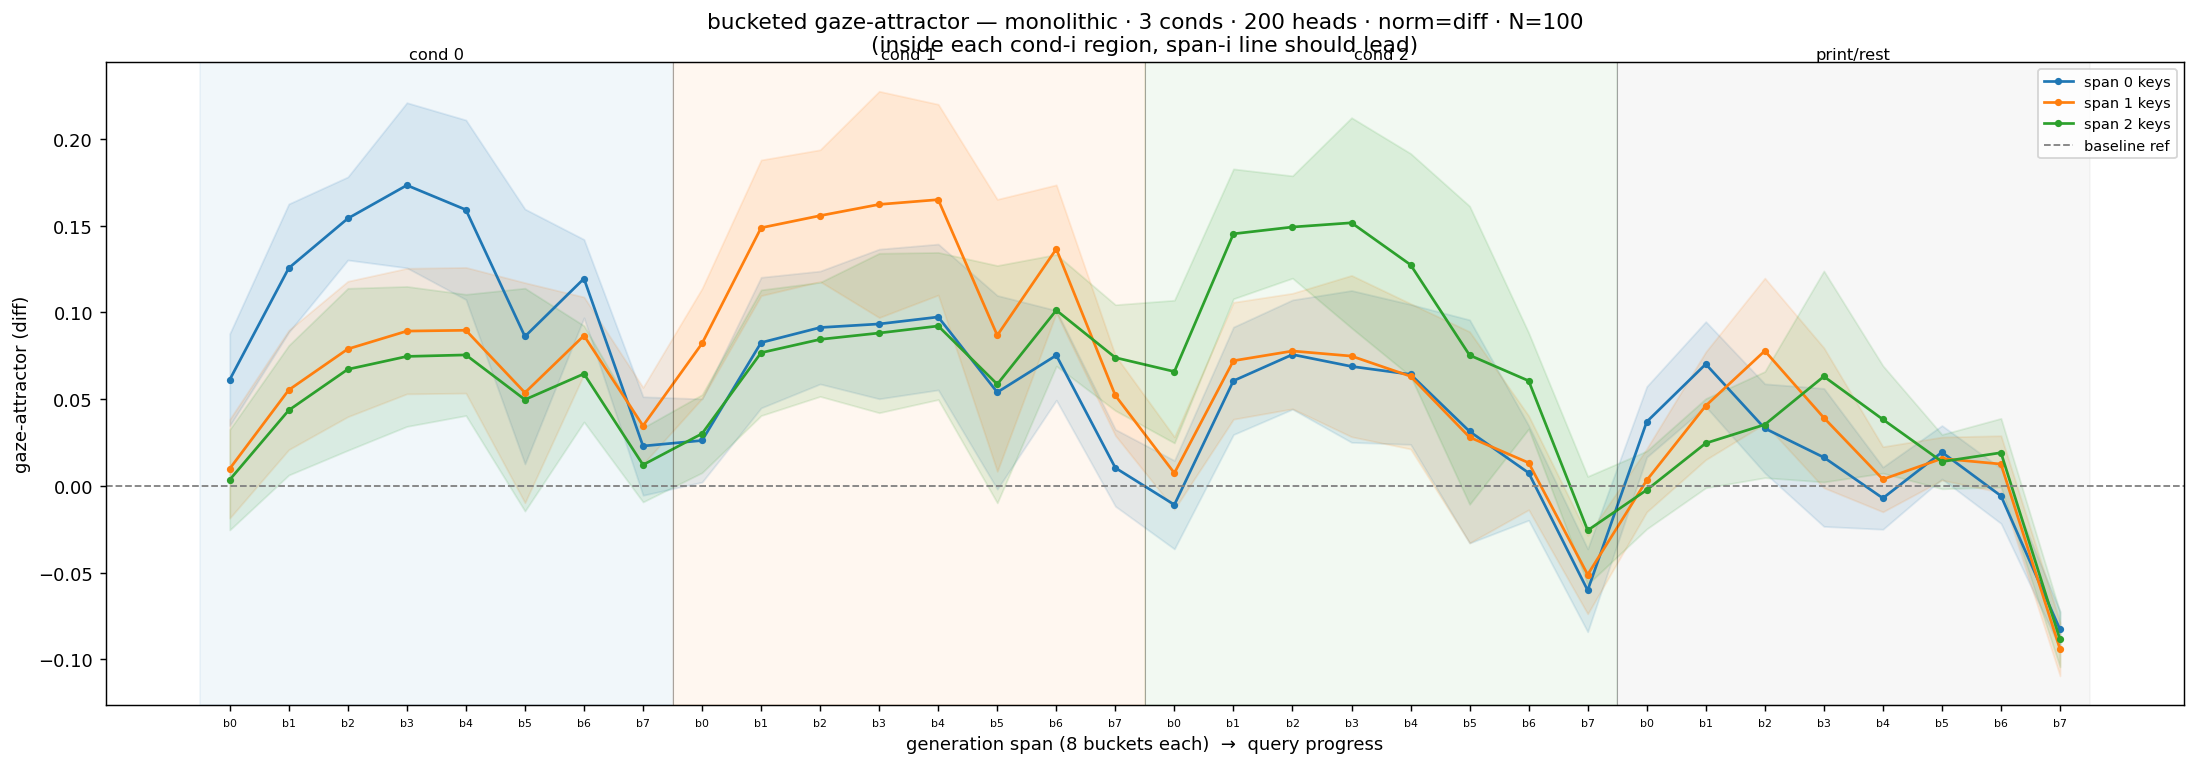

In [ ]:
Mm = np.nanmean(BK_STACK, axis=0)        # (N_QSPAN*NUM_BUCKETS, n_cond)
Ms = np.nanstd(BK_STACK, axis=0)
base_m = np.nanmean(BK_BASE, axis=0)
N = len(BK_USED)
nb_x = N_QSPAN * NUM_BUCKETS
x = np.arange(nb_x)
cmap = plt.get_cmap("tab10")

fig, ax = plt.subplots(figsize=(17, 6))
for j in range(AGG_N_COND):
    col = cmap(j % 10)
    ax.plot(x, Mm[:, j], "-o", ms=3, color=col, label=f"span {j} keys")
    ax.fill_between(x, Mm[:, j] - Ms[:, j], Mm[:, j] + Ms[:, j], color=col, alpha=0.12)

if NORM_MODE == "none":
    ax.plot(x, base_m, "--", color="gray", lw=1.2, label="baseline (non-id prompt)")
else:
    ax.axhline(0 if NORM_MODE == "diff" else 1, color="gray", ls="--", lw=1.0, label="baseline ref")

ymax = ax.get_ylim()[1]
for qs in range(N_QSPAN):
    x0, x1 = qs * NUM_BUCKETS - 0.5, (qs + 1) * NUM_BUCKETS - 0.5
    col = cmap(qs % 10) if qs < AGG_N_COND else (0.5, 0.5, 0.5, 1.0)
    ax.axvspan(x0, x1, color=col, alpha=0.06)
    if qs:
        ax.axvline(x0, color="black", lw=0.6, alpha=0.3)
    ax.text((x0 + x1) / 2, ymax, QSPAN_LABELS[qs], ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels([f"b{b}" for _ in range(N_QSPAN) for b in range(NUM_BUCKETS)], fontsize=6)
ax.set_xlabel(f"generation span ({NUM_BUCKETS} buckets each)  \u2192  query progress")
ax.set_ylabel(f"gaze-attractor ({NORM_MODE})")
ax.set_title(f"bucketed gaze-attractor — {AGG_MODULARITY} \u00b7 {AGG_N_COND} conds \u00b7 "
             f"{AGG_GAZE_N} heads \u00b7 norm={NORM_MODE} \u00b7 N={N}\n"
             f"(inside each cond-i region, span-i line should lead)")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 5. Are the gaze heads *sufficient* for condition → implementation?

§4 shows the gaze heads (L ≥ `LAYER_FLOOR`) **influence** which condition gets implemented. Two
follow-ups:

1. **Dependency** — sink-ablate the gaze heads (force their attention onto token 0, i.e. the
   OV-of-the-first-token "knockout"; Qwen adds no BOS, so token 0 is the chat-start token). If the
   LM can no longer implement the condition, the gaze heads are *necessary*.
2. **Sufficiency** — zero-ablate the **MLP** outputs in those same layers (L ≥ `LAYER_FLOOR`) at the
   generation positions, leaving the gaze heads intact. If implementation is ~unaffected, the
   attention/gaze heads carry the work (the layer-`LAYER_FLOOR`+ MLPs are not needed).

Both reuse §4's greedy non-cached decode + `nn_functional_softmax_0` / MLP-output hooks.

In [32]:
# ── ablation utilities (build on §4's generate_with_head_attn_mask) ──────────
from rich.markup import escape

LAYER_FLOOR = 35       # gaze-head / MLP layers under test (L >= LAYER_FLOOR)
SINK_POS    = 0        # attention-sink target (Qwen has no BOS → token 0 = chat-start token)


def random_heads_in_band(n, lo, hi, seed=0, exclude=()):
    """n random (layer, head) with lo <= layer < hi, excluding `exclude` (and any gaze heads)."""
    rng = _random.Random(seed)
    excl = set(exclude)
    pool = [(l, h) for l in range(lo, hi) for h in range(N_HEADS) if (l, h) not in excl]
    return rng.sample(pool, min(n, len(pool)))


@torch.no_grad()
def generate_with_head_attn_sink(prefill, layer_to_heads, q_start, sink_pos=0, max_new=30):
    """Greedy non-cached decode. For each layer→[heads], force those heads' attention (query rows
    >= q_start) ENTIRELY onto key `sink_pos` by adding -inf to every other key's pre-softmax score
    → the head can only read token `sink_pos` (≈ OV-of-token-0 sink = head knocked out).
    layer_to_heads={} ⇒ unmodified baseline."""
    ids = prepare_input(prompts=[prefill], tokenizer=mt, add_special_tokens=False)["input_ids"]
    gen = []
    for _ in range(max_new):
        seq = ids.shape[1]
        kvec = torch.full((seq,), float("-inf"))
        kvec[sink_pos] = 0.0                      # keep ONLY the sink key
        with mt.trace({"input_ids": ids, "attention_mask": torch.ones_like(ids)},
                      scan=False, validate=False):
            for L in sorted(layer_to_heads):       # ascending = nnsight execution order
                am = get_module_nnsight(mt, mt.attn_module_name_format.format(L))
                sm = am.source.attention_interface_0.source.nn_functional_softmax_0
                km = torch.zeros(1, N_HEADS, seq, seq)
                for h in layer_to_heads[L]:
                    km[0, h, q_start:, :] += kvec
                sm.input = sm.input + km.to(device=sm.input.device, dtype=sm.input.dtype)
            logits = mt.output.logits[:, -1, :].save()
        nxt = int(logits[0].argmax(-1))
        if nxt == mt.tokenizer.eos_token_id:
            break
        gen.append(nxt)
        ids = torch.cat([ids, torch.tensor([[nxt]], device=ids.device)], dim=1)
    return mt.tokenizer.decode(gen, skip_special_tokens=True)


@torch.no_grad()
def generate_with_mlp_ablation(prefill, mlp_layers, q_start, max_new=30):
    """Greedy non-cached decode with the MLP output of every layer in `mlp_layers` ZEROED at query
    rows >= q_start (zero-ablation, multiplicative mask). mlp_layers=[] ⇒ baseline."""
    ids = prepare_input(prompts=[prefill], tokenizer=mt, add_special_tokens=False)["input_ids"]
    gen = []
    for _ in range(max_new):
        seq = ids.shape[1]
        keep = torch.ones(1, seq, 1)
        keep[:, q_start:, :] = 0.0                 # zero the generation region
        with mt.trace({"input_ids": ids, "attention_mask": torch.ones_like(ids)},
                      scan=False, validate=False):
            for L in sorted(mlp_layers):
                mlp = get_module_nnsight(mt, mt.mlp_module_name_format.format(L))
                mlp.output = mlp.output * keep.to(device=mlp.output.device, dtype=mlp.output.dtype)
            logits = mt.output.logits[:, -1, :].save()
        nxt = int(logits[0].argmax(-1))
        if nxt == mt.tokenizer.eos_token_id:
            break
        gen.append(nxt)
        ids = torch.cat([ids, torch.tensor([[nxt]], device=ids.device)], dim=1)
    return mt.tokenizer.decode(gen, skip_special_tokens=True)


gaze_band = [(l, h) for (l, h) in gaze_heads if l >= LAYER_FLOOR]
print(f"{len(gaze_band)} / {len(gaze_heads)} gaze heads in layers >= {LAYER_FLOOR}  "
      f"(layers {sorted({l for l, _ in gaze_band})})")

295 / 350 gaze heads in layers >= 35  (layers [35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62])


In [33]:
print(prefill)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is a prime number
2. n is between 50 and 100 (inclusive)
3. the sum of n's digits is greater than 5
4. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any

In [39]:
ctrl_heads

[(63, 39),
 (47, 32),
 (61, 14),
 (49, 3),
 (36, 10),
 (43, 13),
 (52, 24),
 (51, 21),
 (48, 21),
 (62, 7),
 (63, 24),
 (44, 29),
 (51, 8),
 (46, 34),
 (55, 12),
 (41, 38),
 (52, 7),
 (39, 7),
 (44, 0),
 (39, 8),
 (61, 10),
 (37, 35),
 (56, 18),
 (62, 31),
 (43, 2),
 (53, 15),
 (59, 15),
 (63, 4),
 (55, 34),
 (39, 15),
 (44, 36),
 (37, 39),
 (60, 21),
 (37, 8),
 (58, 33),
 (45, 31),
 (51, 3),
 (54, 12),
 (38, 1),
 (46, 30),
 (49, 25),
 (45, 2),
 (56, 6),
 (57, 7),
 (41, 14),
 (54, 4),
 (63, 27),
 (49, 38),
 (53, 2),
 (43, 15),
 (36, 36),
 (53, 39),
 (35, 15),
 (37, 32),
 (60, 0),
 (48, 15),
 (59, 22),
 (62, 8),
 (58, 5),
 (56, 30),
 (35, 1),
 (56, 7),
 (51, 35),
 (45, 35),
 (42, 35),
 (63, 7),
 (45, 26),
 (59, 13),
 (36, 37),
 (40, 36),
 (54, 21),
 (42, 3),
 (42, 28),
 (39, 10),
 (53, 32),
 (50, 4),
 (37, 26),
 (37, 15),
 (45, 13),
 (52, 15),
 (51, 30),
 (38, 9),
 (44, 27),
 (54, 3),
 (44, 15),
 (59, 18),
 (38, 26),
 (53, 38),
 (45, 33),
 (53, 27),
 (41, 13),
 (55, 35),
 (61, 15),
 (55

In [38]:
### ---- dependency test: sink-ablate the gaze heads (L >= LAYER_FLOOR) ----
DEP_SAMPLE = "cond_0011"     # monolithic sample with >= 3 distinct-predicate conditions
DEP_VAR    = "b"             # assignment we generate (a=cond0, b=cond1, ...)
MAX_NEW    = 32
### --------------------------------------------------------------------------
lab, comp = load_labeled(DEP_SAMPLE, "monolithic")
cut       = cut_after_assignment(lab.generation, DEP_VAR)
prefill   = lab.full_prompt + lab.generation[:cut]
ids       = prepare_input(prompts=[prefill], tokenizer=mt, add_special_tokens=False)["input_ids"]

rich_print(f"[white]{prefill}[/white]")

seq       = ids.shape[1]
q_start   = seq - 1                                # last prefill token writes the first RHS token

l2h = group_heads(gaze_band)
ctrl_heads = random_heads_in_band(len(gaze_band), LAYER_FLOOR, mt.n_layer, seed=0, exclude=gaze_band)
r2h = group_heads(ctrl_heads)

rich_print(f"[bold]dependency test[/bold] · sample={DEP_SAMPLE} · '{DEP_VAR} =' · "
           f"sink {len(gaze_band)} gaze heads (L>={LAYER_FLOOR}) onto token {SINK_POS}")
print(f"natural cached line:  {lab.generation[cut:cut + 70].splitlines()[0]!r}\n")

base = generate_with_head_attn_sink(prefill, {},  q_start, SINK_POS, MAX_NEW)
abl  = generate_with_head_attn_sink(prefill, l2h, q_start, SINK_POS, MAX_NEW)
ctrl = generate_with_head_attn_sink(prefill, r2h, q_start, SINK_POS, MAX_NEW)
rich_print(f"[baseline         no ablation       ]  {DEP_VAR} =[sea_green1]{escape(base)}[/]")
rich_print(f"[ablate gaze      sink L>={LAYER_FLOOR}         ]  {DEP_VAR} =[salmon1]{escape(abl)}[/]")
rich_print(f"[control {len(ctrl_heads):3d} band-random heads]  {DEP_VAR} =[plum1]{escape(ctrl)}[/]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is a perfect square
2. n is even
3. n is a prime number

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = int(n**0.5)**2 == n
    b =

dependency test · sample=cond_0011 · 'b =' · sink 295 gaze heads (L>=35) onto token 0

natural cached line:  ' n % 2 == 0'



b = n % 2 == 0
    c = n > 1 and all(n % i != 0 for i in range(2, int(n

b = n % 2 == 0 or n % 2 == 1
    c = len([i for i in range(2, int(n**

b = n % 2 == 0
    c = all(n % i != 0 for i in range(2, int(n**0.5)

In [46]:
l2h_full = {layer_idx: list(range(N_HEADS)) for layer_idx in range(40, 55)}
abl_full_band  = generate_with_head_attn_sink(prefill, l2h_full, q_start, SINK_POS, MAX_NEW)
rich_print(f"[ablate full L>={LAYER_FLOOR} band]  {DEP_VAR} =[orange1]{escape(abl_full_band)}[/]")

b = n % 2 == 0
    return n
</n>
 to implement the solution, we need to create a function that checks if a number

In [37]:
### ---- sufficiency test: zero-ablate MLP in layers L >= LAYER_FLOOR ----
# reuses prefill / q_start / DEP_VAR / MAX_NEW from the dependency cell above.
mlp_layers = list(range(LAYER_FLOOR, mt.n_layer))

rich_print(f"[bold]sufficiency test[/bold] · zero MLP at layers {LAYER_FLOOR}..{mt.n_layer - 1} "
           f"(query rows >= q_start) — gaze heads left INTACT")
base_m = generate_with_mlp_ablation(prefill, [],         q_start, MAX_NEW)
mlpabl = generate_with_mlp_ablation(prefill, mlp_layers, q_start, MAX_NEW)
rich_print(f"[baseline      no ablation      ]  {DEP_VAR} =[sea_green1]{escape(base_m)}[/]")
rich_print(f"[ablate MLP    zero L>={LAYER_FLOOR}        ]  {DEP_VAR} =[salmon1]{escape(mlpabl)}[/]")

sufficiency test · zero MLP at layers 35..63 (query rows >= q_start) — gaze heads left INTACT

b = n >= 100
    c = n % 2 == 0
    print(f"Condition 1: {a}, Condition 2

b = n n n n n n b b b b b b b b b b b b b b b b b b b b  b b b  